# Import all packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
# using Turing
# using MCMCChains
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using CmdStan
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using BlackBoxOptim
using BlackBoxOptim: num_func_evals
using HypothesisTests
using BayesianOptimization, GaussianProcesses

# using CairoMakie
# using PairPlots
# using DataFrames

set_cmdstan_home!("C:\\cmdstan\\cmdstan-2.30.0");

┌ Warning: Environment variable CMDSTAN_HOME not set. Use set_cmdstan_home!.
└ @ CmdStan C:\Users\dgomez\.julia\packages\CmdStan\2vwWj\src\CmdStan.jl:27


In [2]:
include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesInfs.jl")
include("D:\\David\\BayesianInferencesInVivoScripts\\ModelFunctionsAll.jl")
include("D:\\David\\BayesianInferencesInVivoScripts\\FunctionsBayesOED.jl")

include("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\FunctionsInferenceScallable.jl")

CompRepUtil_Entro_OEDmc2 (generic function with 1 method)

# Define Priors

In [3]:
priorTheta, priotY0, sampsTh, sampsY0 = genPriorSamps(8000);
bounds, boundY0 = genThetaBounds();


# Extract Experimental Data 3.2 mM

In [4]:
mainpath = "D:\\David\\BayesianInferencesInVivoScripts\\ProcessedData\\";
i = 1;
paths = [mainpath*"3Mil_3-2mMPyr_Dat.csv"];
conce = [3.2];


Random.seed!(8987654);
global dat = restructDatInfCompRep_RealExpDat_Scal(paths, conce, rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], rand(priotY0[i], 1)[1], [3e6])

Dict{String, Any} with 16 entries:
  "Means"  => [9177.49; 6162.55; … ; -6.00262; 5.56735;;; 0.0; 34.6837; … ; -0.…
  "stsl"   => [77;;]
  "obSta"  => [1 2]
  "sts"    => [0; 20; … ; 390; 395;;]
  "obser"  => 2
  "Y0us"   => [3200.0; 0.0; … ; 0.0; 9177.49;;]
  "ts"     => [1.0e-20; 1.0; … ; 394.0; 395.0;;]
  "itp"    => [0.0]
  "ScFms"  => [23.8997;;]
  "ncells" => [4;;]
  "stslm"  => 77
  "tml"    => 396
  "Erros"  => [821.947; 491.932; … ; 7.38584; 6.8147;;; 1.0; 4.36114; … ; 6.420…
  "m"      => 1
  "nmCls"  => [3.0e6;;]
  "nts"    => [395;;]

1

# Simulate Experiment Prior Prediction
CAREFUL!!! Simulations take a minute or more if you take all the samples!

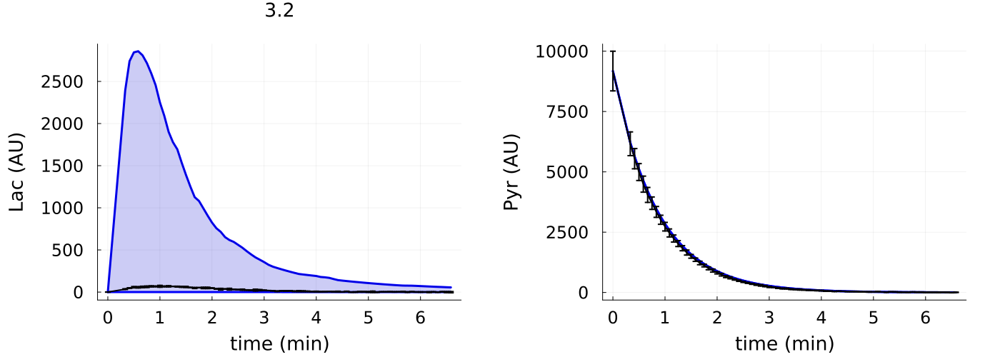

In [5]:
simPriorPredictAll(2000, dat, sampsTh, sampsY0, conce)

# MLE to obtain a good first guess for inference

In [6]:
p = [48, 51.23, 0.044, 0.02, 0.02, 0.001, 0.01, 0.0003, 0.0001, 0.0002, 1e-1, 1e-6, 3e6, 50/(15*0.12), 5000/(15*0.12), 700/(15*0.12)];
ObjectFunctMECp_Multi_MLE2(p)

6.268071459474408e15

In [19]:
Iters = 1;
CCsT = Array{Any}(undef,Iters);
FitsT = Array{Any}(undef,Iters);

i=1
fitness_progress_history = Array{Tuple{Int, Float64},1}()
callback = oc -> push!(fitness_progress_history, (num_func_evals(oc), best_fitness(oc)))

resM = bboptimize(ObjectFunctMECp_Multi_MLE2; SearchRange = vcat([(bounds[1][i], bounds[2][i]) for i in 1:13], [(boundY0[1][i], boundY0[2][i]) for i in 1:3]), # T1_X, T1_P, kin, kpl, kf, kr, a1, a2, a3, b1, b2, b3
        MaxTime = 60*5, method = :adaptive_de_rand_1_bin, 
        CallbackFunction = callback, CallbackInterval = 0.0)

CCsT[i] = fitness_progress_history;
FitsT[i] = resM;

Starting optimization with optimizer DiffEvoOpt{FitPopulation{Float64}, RadiusLimitedSelector, BlackBoxOptim.AdaptiveDiffEvoRandBin{3}, RandomBound{ContinuousRectSearchSpace}}
0.00 secs, 0 evals, 0 steps
0.51 secs, 146 evals, 86 steps, improv/step: 0.419 (last = 0.4186), fitness=285.437212644
1.02 secs, 296 evals, 197 steps, improv/step: 0.381 (last = 0.3514), fitness=249.894136702
1.54 secs, 468 evals, 347 steps, improv/step: 0.340 (last = 0.2867), fitness=249.848656050
2.05 secs, 653 evals, 526 steps, improv/step: 0.308 (last = 0.2458), fitness=249.848656050
2.55 secs, 836 evals, 704 steps, improv/step: 0.278 (last = 0.1910), fitness=249.848656050
3.06 secs, 1028 evals, 892 steps, improv/step: 0.253 (last = 0.1596), fitness=243.203535532
3.57 secs, 1212 evals, 1078 steps, improv/step: 0.238 (last = 0.1667), fitness=243.203535532
4.16 secs, 1404 evals, 1272 steps, improv/step: 0.217 (last = 0.0979), fitness=243.203535532
4.67 secs, 1593 evals, 1462 steps, improv/step: 0.204 (last = 0.

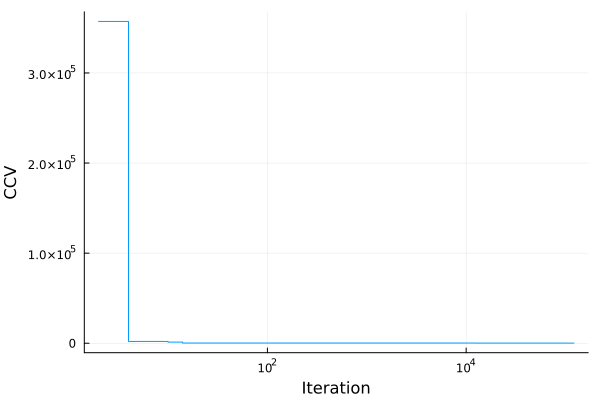

┌ Warning: Attempting to store var"#107#108".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447
┌ Warning: Attempting to store BlackBoxOptim.var"#114#115".
│ JLD2 only stores functions by name.
│  This may not be useful for anonymous functions.
└ @ JLD2 C:\Users\dgomez\.julia\packages\JLD2\nPYlZ\src\data\writing_datatypes.jl:447


In [21]:
# Plot convergence curve
pl=plot(CCsT[1], xaxis=:log, linetype=:step, label = "", xlabel = "Iteration", ylabel = "CCV")
display(pl)

# Extract Parameter Vector
parfitT = zeros(16, Iters);
for i in 1:Iters
    parfitT[:,i] = best_candidate(FitsT[i]);
end
bestPind = findfirst([CCsT[i][end][2] for i in 1:length(CCsT)] .== minimum([CCsT[i][end][2] for i in 1:length(CCsT)]))
ppT = parfitT[:,bestPind];

# Save Data
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMTRRCmp_Exper_Iter1.jld2", "FitsT",FitsT)
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMVectTRRCmp_Exper_Iter1.jld2", 
        "resMMat",parfitT, "CCsT", CCsT)

In [22]:
# Load Data
ppT = JLD2.load("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\MLEResults\\resMVectTRRCmp_Exper_Iter1.jld2")["resMMat"][:,1]

16-element Vector{Float64}:
   43.43491950510104
   51.23
    0.0016506747207743941
    0.0233421439086888
    1.5575827012941228e-6
    1.769800336358783e-7
    0.050143712668535054
    1.9999528948761933
    0.022427392012726786
    4.175478884716051e-6
    0.6701299196169221
    0.0044911067760173996
    3.0e6
 1407.95484026085
 7749.514915704915
    0.016771969563142138

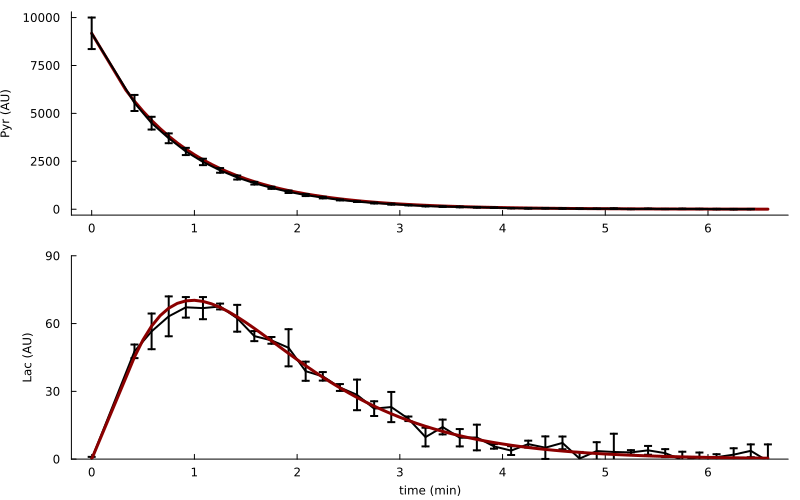

In [23]:
pst = Array{Any}(undef, length(conce))
i = 1
for i in 1:length(conce)
     tsC2 = dat["sts"][:,i];
     if i == 3
          tsC2 = dat["sts"][1:end-1,3];
     end
     ts = 0:tsC2[end];
     ivss = [round(conce[i], digits = 1)*1000, 0, 0, ppT[14], ppT[15], ppT[16], 0, 0, 0, 0, 0, round(conce[i], digits = 1)*1000, 0, round(conce[i], digits = 1)*1000*(dat["ScFms"][i]*0.12)];;
     samps = convert.(Int, tsC2);

     SimulsAll, SimulsAll2, SimulsAll3 = PyruvateHP_NMR_SolveAllCp_Scall(ts, vcat(ppT[1:13], dat["ScFms"][i], 0), ivss, samps);

     pps = plot(dat["sts"][1:2:end,i]./60, dat["Means"][1:2:end,i,2], yerror = dat["Erros"][1:2:end,i,2], linewidth = 2, colour = "black", label = "",
               margin=1Plots.mm,xtickfont=font(8), ytickfont=font(8), guidefont=font(8), titlefont=font(18),
               xlabel = "time (min)", ylabel = "Lac (AU)", size = (800,500))

          plot!(tsC2./60, SimulsAll[:,13,1], linewidth=3, colour="red4", label = "", grid = false, ylim=(0,90))


     ps = plot(tsC2./60, SimulsAll[:,14,1], linewidth=3, colour="red4", label = "", grid = false,
          margin=1Plots.mm,xtickfont=font(8), ytickfont=font(8), guidefont=font(8), titlefont=font(18))
     plot!(dat["sts"][1:2:end-1,i]./60, dat["Means"][1:2:end-1,i,1], yerror = dat["Erros"][1:2:end-1,i,1], linewidth = 2, colour = "black", label = "", ylabel = "Pyr (AU)")

     pst[i] = plot(ps, pps, layout=(2,1))
end

plot(pst...)

## Compute structure for Stan's initial guess

In [24]:
jj = vcat(1, 3:12)

preTrans = zeros(14);

for i in 1:length(jj)
    
    if i == 1
        preTrans[i] = (ppT[jj[i]]-priorTheta[jj[i]].μ)/priorTheta[jj[i]].σ;
    else
        preTrans[i] = (ppT[jj[i]]-priorTheta[jj[i]].untruncated.μ)/priorTheta[jj[i]].untruncated.σ;
    end
    
end
kk = [14,15,16]
for i in 1:length(priotY0)
    preTrans[i+11] = (ppT[kk[i]]-priotY0[i].untruncated.μ)/priotY0[i].untruncated.σ;
end


samps = hcat(preTrans,preTrans,preTrans,preTrans);
names = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];

ini = genStanInitDict2(repeat(preTrans, 1, 10), names)

ini[1]

Dict{String, Any} with 14 entries:
  "kbnE" => 0.391826
  "LDH"  => -1.95818
  "kin"  => -0.33973
  "ki"   => -0.2946
  "kunE" => -0.775726
  "kpl"  => -0.151195
  "NADH" => 3.99561
  "kup"  => 1.10521
  "T1_X" => 0.251492
  "kbp"  => -0.947217
  "kr"   => 3.99012
  "NAD"  => 3.62481
  "kun"  => -0.999999
  "kbn"  => 2.11517

# Inference

In [25]:
modelpath = "D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\HP_PyrLac_CmpRepresMo_Scallable2.stan";
stream = open(modelpath,"r");
Model = read(stream,String);
close(stream);

StanModel = Stanmodel(name="PyrCompRepr_Iter1_Try5", model=Model, nchains =10,
            num_samples  = 800, num_warmup = 200, printsummary=true);
StanModel.method.save_warmup = true;
StanModel.method.adapt.delta = 0.90;
# StanModel.method.algorithm.stepsize = 0.1;
StanModel.method.algorithm.engine.max_depth=11;
StanModel.method.algorithm.stepsize_jitter = 0.5;

In [26]:
rc, chns, cnames = stan(StanModel, dat, init = ini) 


Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: CVode(cvodes_mem, t_final, nv_state_, &t_init, CV_NORMAL) failed with error flag -4: 
Convergence test failures occurred too many times during one internal time step or minimum step size was reached. (in 'd:/David/BayesianInferencesInVivoScripts/ExperimentalBayesianOED_NewPriorsAll/tmp/PyrCompRepr_Iter1_Try5.stan', line 230, column 6 to column 137)
If this warning occurs sporadically, such as for highly constrained variable types like covariance matrices, then the sampler is fine,
but if this warning occurs often then your model may be either severely ill-conditioned or misspecified.

Informational Message: The current Metropolis proposal is about to be rejected because of the following issue:
Exception: CVode(cvodes_mem, t_final, nv_state_, &t_init, CV_NORMAL) failed with error flag -4: 
Convergence test failures occurred too many times during one internal time ste


An error occurred while running the previously compiled Stan program.

Please check the contents of file PyrCompRepr_Iter1_Try5_run.log and the'command' field in the Stanmodel, e.g. stanmodel.command.



ErrorException: Return code = -5

In [27]:
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PyrCompetitiveRepressionInferExpScal_Iter1_Try5.jld", "rc", rc, "chns", chns, "cnames", cnames)

poster = vcat(chns[201:end, end-16:end, 1], chns[201:end, end-16:end, 2], chns[201:end, end-16:end, 3], chns[201:end, end-16:end, 4], chns[201:end, end-16:end, 5], 
              chns[201:end, end-16:end, 6], chns[201:end, end-16:end, 7], chns[201:end, end-16:end, 8], chns[201:end, end-16:end, 9], chns[201:end, end-16:end, 10])
JLD2.save("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter1_Try5.jld", "poster", poster)
CSV.write("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter1_Try5.csv", DataFrame(poster, :auto))

UndefVarError: UndefVarError: `rc` not defined

In [28]:
poster = Matrix(CSV.read("D:\\David\\BayesianInferencesInVivoScripts\\ExperimentalBayesianOED_NewPriorsAll\\Results\\PosteriorCompetitiveRepressionExpScal_Iter1_Try5.csv", DataFrame))

ArgumentError: ArgumentError: "D:\David\BayesianInferencesInVivoScripts\ExperimentalBayesianOED_NewPriorsAll\Results\PosteriorCompetitiveRepressionExpScal_Iter1_Try5.csv" is not a valid file or doesn't exist

# Plot Posterior VS Prior

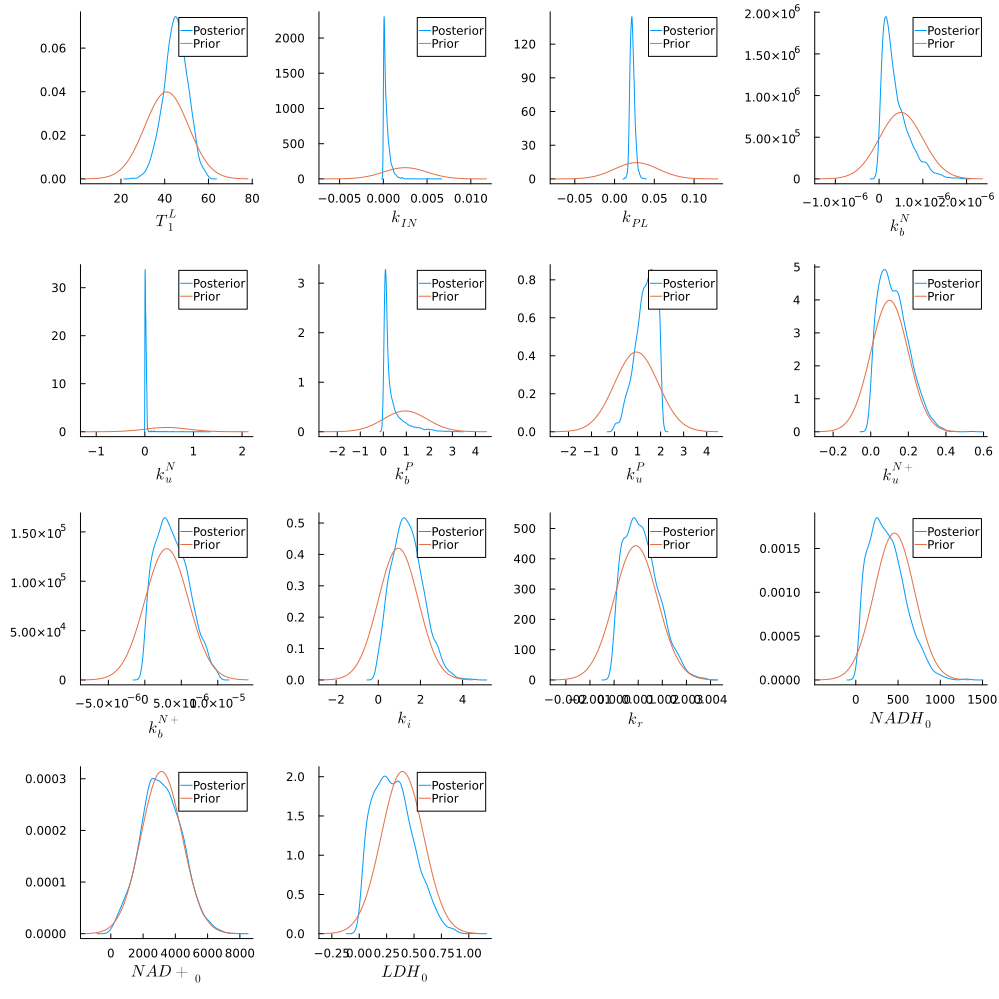

In [248]:
# namess = ["T1_X","kin","kpl","kbn","kun","kbp","kup","kunE","kbnE","ki","kr","NADH","NAD","LDH"];
namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"];

indss=vcat(1, 3:12, 15:17)
prisDis = vcat(priorTheta, priotY0)

pltsPost = Array{Any}(undef, length(indss))

for i in 1:length(indss)

    pltsPost[i] = plot(kde(poster[:,indss[i]][poster[:,7] .> 0.05]), label = "Posterior", xlabel = namess[i])
    try
        plot!(prisDis[indss[i]].untruncated, label = "Prior")
    catch
        plot!(prisDis[indss[i]], label = "Prior")
    end

end

plot(pltsPost..., size=(1000,1000), grid = false)

In [245]:
-log(det(cov(hcat(poster[:,1], poster[:,3:12], poster[:,15:end]))))

87.70916799050057

In [210]:
using CairoMakie
using PairPlots
using DataFrames

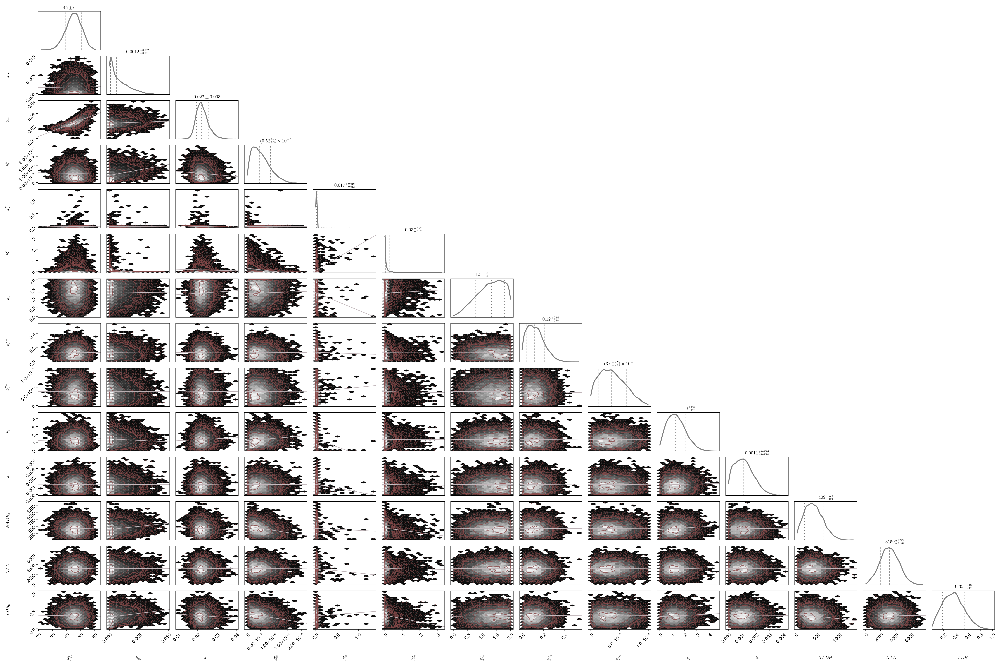

In [211]:
label = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_r",L"NADH_0",L"NAD+_0",L"LDH_0"]

postCut = hcat(poster[:,1], poster[:,3:12], poster[:,15:end]);
df = DataFrame(postCut, :auto)

fig = Figure(size=(3000,2000))
# 
pairplot(fig[1,1], df => (
    PairPlots.HexBin(colormap=:grays, alpha=1), # RdYlGn
    PairPlots.Scatter(filtersigma=2, color="#884a4aff", markersize=3, alpha=0.65),
    PairPlots.Contour(color="#884a4aff", alpha=0.85),
    # # New:
    
    PairPlots.MarginConfidenceLimits(),
    PairPlots.MarginDensity(color="gray", linewidth=3),
    PairPlots.TrendLine(color="#c0b5b9ff"), # default is red
    
), 
labels = Dict(:x1 => label[1],:x2 => label[2],:x3 => label[3],:x4 => label[4],:x5 => label[5],:x6 => label[6],:x7 => label[7],:x8 => label[8],:x9 => label[9],:x10 => label[10],
              :x11 => label[11],:x12 => label[12],:x13 => label[13],:x14 => label[14]))

# save("D:\\David\\BayesianInferencesInVivoScripts\\Figures\\SuppFig6Stuff\\PosteriorCovariance_InitialExperiment.svg", fig)


fig

# Simulate Experiment Current Posterior

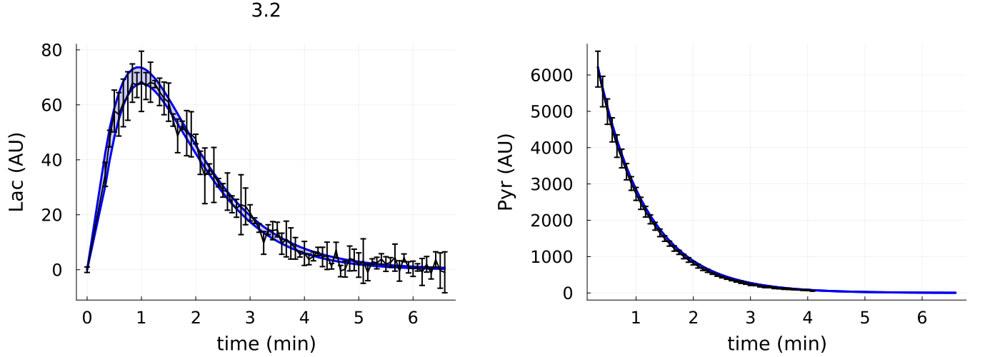

In [213]:
simPriorPredictAll(8000, dat, poster[:,1:14], poster[:,15:end], conce)

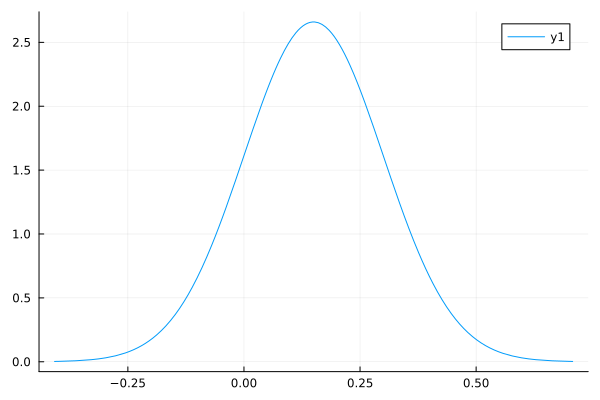

In [251]:
plot(Normal(0.15,0.15))